# When does an outbreak take off? The threshold R0 = 1

**Question:** A first case appears in a population where nobody is immune. For which contact and recovery rates does it start an outbreak at all, and what share of the population has to be immune beforehand for the outbreak to fail?

- **Level:** 1, Fundamentals
- **Prerequisites:** topic 01-getting-started
- **Reading time:** about 25 minutes

## Objectives

By the end of this notebook you can say, from $\beta$ and $\gamma$ alone, whether an outbreak will take off; see the threshold in the engine's output, both in how fast the infected grow in the first week and in how high the epidemic peaks; and compute the share of the population that must be immune to stop it.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with the exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

This example product publishes no package of its own: its method lives in `data-pipeline/pipeline/`, so the notebook imports that code by its path. A product imports its own PyPI package instead (`pip install <package>==<version>`).

The next cell imports the tools and the pipeline's modules, prints the versions and defines the reader of the cases' parameters.

In [1]:
# the tools, their versions, the pipeline's modules and the reader of the cases' parameters
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.baseline import peak_frac
from pipeline.model.sir import simulate

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2


## Data

The parameters of the five cases of the example.

- Owner: this repository (the product template's example), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Licence class: synthetic data produced by the pipeline from the parameters in each manifest (`real_or_synthetic` is `synthetic`); no third-party dataset, so no dataset licence applies, and the repository's MIT licence covers the artifacts.
- Files read: `data/derived/manifests/index.json` and `data/derived/manifests/<case>.json`, for the parameters only; every course shown here is computed by the engine.

## Method

The basic reproduction ratio $R_0$ is the number of people that one infected person infects, on average, in a population where everybody is susceptible (Diekmann, Heesterbeek and Metz, 1990). In the SIR model an infected person meets $\beta$ people per day and stays infectious for $1 / \gamma$ days, so $R_0 = \beta / \gamma$. At the start $S \approx N$, the equation for the infected becomes $dI/dt \approx (\beta - \gamma) I$, and $I$ grows exponentially at rate $\gamma (R_0 - 1)$ when $R_0 > 1$ and decays when $R_0 < 1$. For compartmental models in general the condition $R_0 < 1$ is exactly the stability of the disease-free state (van den Driessche and Watmough, 2002).

If a share $v$ of the population is immune before the outbreak, an infected person meets susceptible people only $(1 - v)$ of the time and the effective ratio is $R_0 (1 - v)$. It drops below 1 when $v > 1 - 1/R_0$, the herd threshold. The engine has no immune compartment, but immunising a share $v$ is the same as running it on a population of $(1 - v) N$ people with the contact rate $\beta (1 - v)$, because the infection pressure $\beta / N$ then stays unchanged. The notebook uses that equivalence.

The first cell prints $R_0$ for the five cases on file and, where it exceeds 1, the herd threshold. It runs no simulation; it is the arithmetic the rest of the notebook will test against the engine.

In [2]:
# the five cases with R0 = beta / gamma and, where R0 is above 1, the herd threshold 1 - 1 / R0
for case_id in CASES:
    p = params_of(case_id)
    r0 = p.beta / p.gamma
    threshold = f"{1 - 1 / r0:.3f}" if r0 > 1 else "none (R0 <= 1)"
    print(f"{case_id:18s} R0 = {r0:5.2f}   herd threshold: {threshold}")

CTRL_degenerate    R0 =  2.00   herd threshold: 0.500
EX01_subcritical   R0 =  0.72   herd threshold: none (R0 <= 1)
EX02_epidemic      R0 =  2.75   herd threshold: 0.636
EX03_fast_burn     R0 =  6.00   herd threshold: 0.833
EX04_slow_spread   R0 =  1.20   herd threshold: 0.167


Only the sub-critical case, at 0.72, sits below 1. The control has $R_0 = 2.00$ but nobody infected to start with, so there is nothing to grow, and the other three have $R_0$ of 1.20, 2.75 and 6.00. The next cell runs the engine on every case that has infected people and divides the peak by the number infected on day 0. If $R_0$ is the threshold, the sub-critical case should not grow at all and the others should grow by a large factor.

In [3]:
# run the cases that have infected people and set each peak against the people infected at the start
for case_id in CASES:
    p = params_of(case_id)
    if p.I0 == 0:
        continue
    r = simulate(p)
    print(f"{case_id:18s} R0 = {p.beta / p.gamma:5.2f}  I0 = {p.I0:4.0f}", end="  ")
    print(f"peak {r.peak_I:7.0f} on day {r.t_peak:6.2f}  x{r.peak_I / p.I0:6.1f}")

EX01_subcritical   R0 =  0.72  I0 =   50  peak      50 on day   0.00  x   1.0
EX02_epidemic      R0 =  2.75  I0 =   50  peak   27345 on day  24.25  x 546.9
EX03_fast_burn     R0 =  6.00  I0 =  100  peak   55265 on day   9.25  x 552.7
EX04_slow_spread   R0 =  1.20  I0 =   50  peak    1521 on day  96.25  x  30.4


The sub-critical case multiplies its 50 initial infections by exactly 1.0: its peak is day 0. The slow spread, with an $R_0$ only 20 percent above 1, multiplies them by 30, and the epidemic and the fast burn by about 550. So the threshold shows, but three cases are too few to see its shape. The next cell sweeps $R_0$ from 0.5 to 4 in steps of 0.1, with the recovery rate of the epidemic case fixed and the contact rate changed, and runs the engine at each value. For each run it fits a straight line to the logarithm of the infected people over the first week, whose slope is the observed growth rate, and records the peak as a share of the population. It prints four values next to the theory: the rate $\gamma (R_0 - 1)$ and the analytic peak of the baseline.

In [4]:
# sweep R0 from 0.5 to 4 with the recovery rate of the epidemic case, and run the engine at every value
base = params_of("EX02_epidemic")
r0_grid = np.linspace(0.5, 4.0, 36)
growth = []
peak_share = []
for r0 in r0_grid:
    r = simulate(replace(base, beta=r0 * base.gamma))
    growth.append(np.polyfit(r.t[:29], np.log(r.I[:29]), 1)[0])
    peak_share.append(r.peak_I / base.N)
baseline = [peak_frac(r0) for r0 in r0_grid]
for r0 in (0.5, 1.0, 2.0, 4.0):
    k = int(np.argmin(np.abs(r0_grid - r0)))
    print(f"R0 = {r0:3.1f}  growth {growth[k]:+.3f}  gamma (R0 - 1) = {base.gamma * (r0 - 1):+.3f}", end="  ")
    print(f"peak share {peak_share[k]:.4f}  analytic {baseline[k]:.4f}")

R0 = 0.5  growth -0.101  gamma (R0 - 1) = -0.100  peak share 0.0005  analytic 0.0000
R0 = 1.0  growth -0.000  gamma (R0 - 1) = +0.000  peak share 0.0005  analytic 0.0000
R0 = 2.0  growth +0.195  gamma (R0 - 1) = +0.200  peak share 0.1555  analytic 0.1534
R0 = 4.0  growth +0.555  gamma (R0 - 1) = +0.600  peak share 0.4137  analytic 0.4034


The next cell draws the growth rate and the peak share against $R_0$ in two panels, with the threshold $R_0 = 1$ marked.

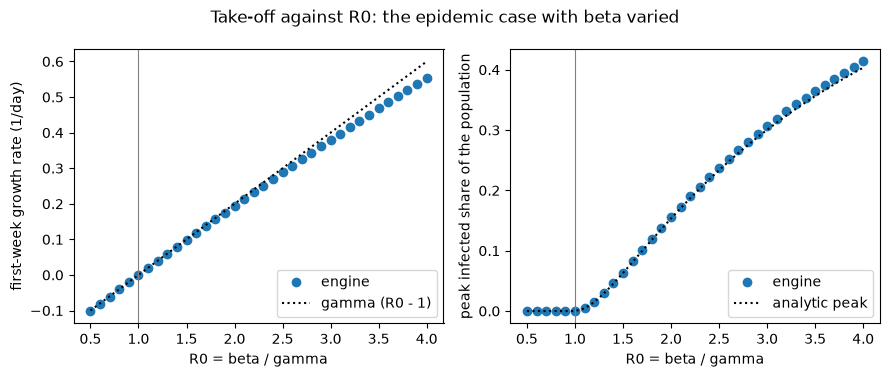

In [5]:
# draw the first-week growth rate and the peak share against R0, with the threshold R0 = 1 marked
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.8))
left.plot(r0_grid, growth, "o", label="engine")
left.plot(r0_grid, base.gamma * (r0_grid - 1), "k:", label="gamma (R0 - 1)")
right.plot(r0_grid, peak_share, "o", label="engine")
right.plot(r0_grid, baseline, "k:", label="analytic peak")
ylabels = ("first-week growth rate (1/day)", "peak infected share of the population")
for ax, ylabel in zip((left, right), ylabels):
    ax.axvline(1.0, color="grey", linewidth=0.8)
    ax.set_xlabel("R0 = beta / gamma")
    ax.set_ylabel(ylabel)
    ax.legend()
fig.suptitle("Take-off against R0: the epidemic case with beta varied")
fig.tight_layout()
plt.show()

The left panel is the threshold itself: the first-week growth rate crosses zero exactly at $R_0 = 1$ and follows the line $\gamma (R_0 - 1)$, a little below it at large $R_0$ because by the end of the week the susceptible people have already started to run out. The right panel shows how little a high rate matters just above the threshold: the peak stays at about one percent of the population or less up to $R_0 = 1.2$ and then climbs steeply, tracking the analytic peak of the baseline. The figure does not show time. An outbreak with $R_0$ just above 1 does take off, but how late is what the next cell shows.

In [6]:
# look closely around the threshold: the engine at R0 = 0.9, 1.0, 1.1, 1.2 and 1.5
for r0 in (0.9, 1.0, 1.1, 1.2, 1.5):
    r = simulate(replace(base, beta=r0 * base.gamma))
    print(f"R0 = {r0:3.1f}  peak {r.peak_I:6.0f}  on day {r.t_peak:6.2f}  attack rate {r.attack_rate:.4f}")

R0 = 0.9  peak     50  on day   0.00  attack rate 0.0047
R0 = 1.0  peak     50  on day   0.00  attack rate 0.0147
R0 = 1.1  peak    465  on day 160.00  attack rate 0.0749
R0 = 1.2  peak   1520  on day 120.25  attack rate 0.2542
R0 = 1.5  peak   6379  on day  64.50  attack rate 0.5845


At $R_0 = 0.9$ and at $R_0 = 1.0$ the peak is the 50 initial infections on day 0. At $R_0 = 1.1$ the infected are still growing when the 160 days end: the peak printed, on day 160.00, is the last day and not a true peak. At 1.2 the peak comes at day 120.25 and at 1.5 at day 64.50. Close above the threshold the outbreak exists but is slow, so a horizon that is too short mistakes it for no outbreak. The last question of the notebook is the herd threshold: the cell runs the epidemic case with a share $v$ of the population immune, from 0 to 0.8 in steps of 0.05, and prints the threshold $1 - \gamma/\beta$ with the infected share for three values of $v$.

In [7]:
# immunise a share v of the population first: the same engine with the contact rate and the population scaled by 1 - v
shares = np.linspace(0.0, 0.8, 17)
final_share = []
for v in shares:
    scaled = replace(base, beta=base.beta * (1 - v), N=base.N * (1 - v))
    final_share.append(simulate(scaled).R[-1] / base.N)
herd = 1 - base.gamma / base.beta
print(f"herd threshold: {herd:.3f}")
for v in (0.3, 0.6, 0.7):
    k = int(np.argmin(np.abs(shares - v)))
    print(f"v = {v:.1f}  infected share {final_share[k]:.4f}")

herd threshold: 0.636
v = 0.3  infected share 0.5446
v = 0.6  infected share 0.0496
v = 0.7  infected share 0.0028


The next cell draws the infected share against the immune share, with the herd threshold marked.

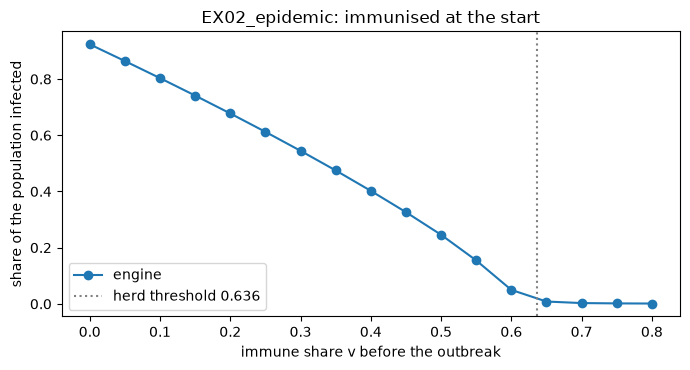

In [8]:
# draw the share of the population infected against the immune share, with the herd threshold marked
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(shares, final_share, "o-", label="engine")
ax.axvline(herd, color="grey", linestyle=":", label=f"herd threshold {herd:.3f}")
ax.set_xlabel("immune share v before the outbreak")
ax.set_ylabel("share of the population infected")
ax.set_title("EX02_epidemic: immunised at the start")
ax.legend()
fig.tight_layout()
plt.show()

The curve falls steeply and reaches the floor at the dotted line: with 30 percent immune the outbreak still infects 0.5446 of the population, with 60 percent only 0.0496, and with 70 percent, past the herd threshold of 0.636, 0.0028, which are the 50 initial infections and the handful they infect. The threshold is the point where the outbreak stops being able to feed itself. The figure treats immunity as perfect and uniform, and that is an assumption of the model and not a finding: a vaccine that protects only part of those it reaches, or immune people who cluster, would move the line to the right.

## Results

**Answer:** An outbreak takes off exactly when $R_0 = \beta / \gamma$ exceeds 1. In the engine the first-week growth rate is -0.101 per day at $R_0 = 0.5$, about 0 at 1.0, 0.195 at 2.0 and 0.555 at 4.0, against the theoretical -0.100, 0.000, 0.200 and 0.600 of $\gamma (R_0 - 1)$. The slow spread, with $R_0 = 1.20$, multiplies its 50 initial infections by 30.4 and peaks on day 96.25, while the sub-critical case, at 0.72, never exceeds its starting 50. To prevent an outbreak in the epidemic case, with $R_0 = 2.75$, 0.636 of the population must be immune beforehand: at 0.6 the outbreak still reaches 0.0496 of the population and at 0.7 only 0.0028.

The result is for a closed, well-mixed population with perfect and uniform immunity. It holds for the threshold; it says nothing yet about how large an outbreak above the threshold becomes, which is the question of the next notebook, and the near-threshold runs showed that a short horizon hides slow outbreaks.

## Summary

- An outbreak takes off when $R_0 = \beta / \gamma$ is above 1, and the engine's first-week growth rate follows $\gamma (R_0 - 1)$ and crosses zero at 1.
- Just above the threshold the outbreak is real but slow: at $R_0 = 1.1$ it has not peaked after 160 days.
- The share that must be immune to stop the epidemic case is $1 - 1/R_0 = 0.636$.
- Next: how large the outbreak gets once it takes off, in notebook 02 of this topic.

## References

- Diekmann, O., Heesterbeek, J. A. P. and Metz, J. A. J. (1990). On the definition and the computation of the basic reproduction ratio R0 in models for infectious diseases in heterogeneous populations. Journal of Mathematical Biology. https://doi.org/10.1007/BF00178324
- van den Driessche, P. and Watmough, J. (2002). Reproduction numbers and sub-threshold endemic equilibria for compartmental models of disease transmission. Mathematical Biosciences. https://doi.org/10.1016/S0025-5564(02)00108-6
- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- The engine and the baseline of this repository, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`, `pipeline/model/baseline.py`).